<a href="https://colab.research.google.com/github/Murcha1990/ML_AI26/blob/main/Week1_Intro_EDA/AdvancedEDA_Pro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Advanced analytics

## Цели на сегодня

* дашборды: аналитика в одну строчку

* анализ признаков относительно целевой переменной (оттока)

* изучение взаимосвязи факторов

* причём здесь статистика: интуиция статистических тестов

* итог: инсайты и гипотезы по результатам EDA

Мы будем работать с датасетом про отток клиентов телекома - в нем содержатся различные характеристики клиентов и информация об оттоке.

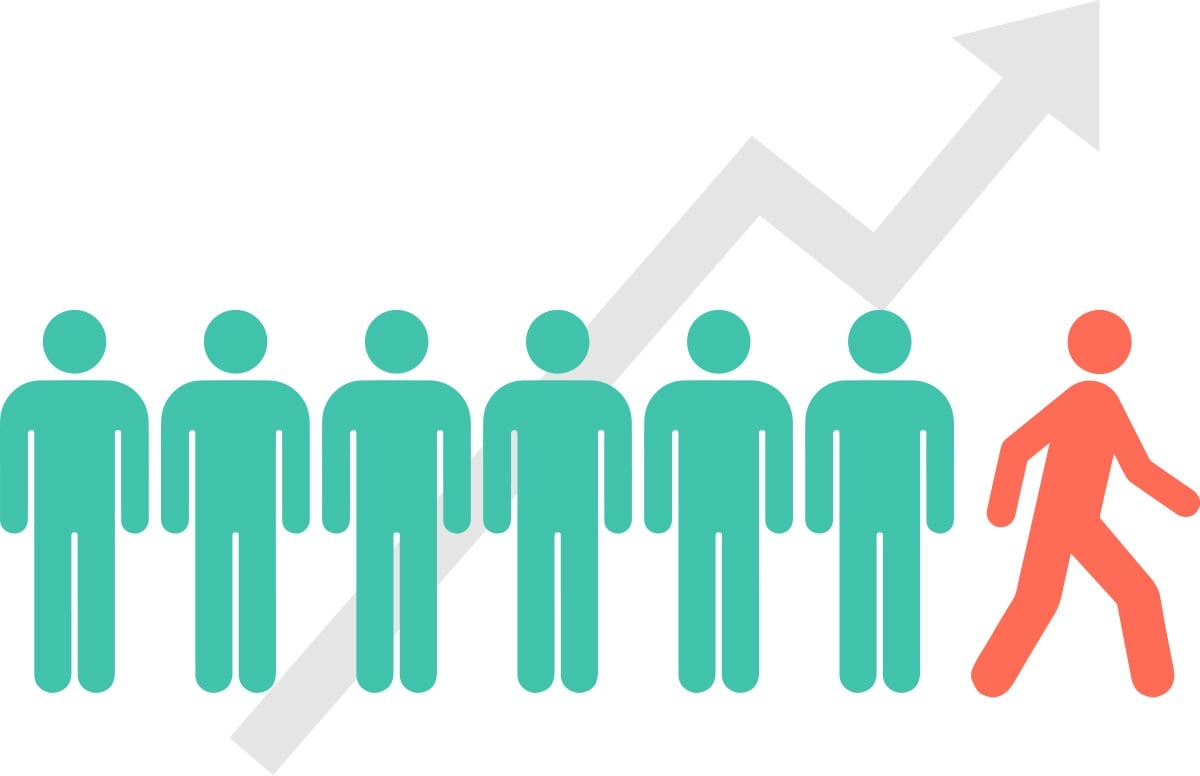

## Описание данных

* `gender` - Whether the customer is a male or a female

* `SeniorCitizen` - Whether the customer is a senior citizen or not (1, 0)

* `Partner` - Whether the customer has a partner or not (Yes, No)

* `Dependents` - Whether the customer has dependents or not (Yes, No)

* `tenure` - Number of months the customer has stayed with the company

* `PhoneService` - Whether the customer has a phone service or not (Yes, No)

* `MultipleLines` - Whether the customer has multiple lines or not (Yes, No, No phone service)

* `InternetService` - Customer’s internet service provider (DSL, Fiber optic, No)

* `OnlineSecurity` - Whether the customer has online security or not (Yes, No, No internet service)

* `OnlineBackup` - Whether the customer has online backup or not (Yes, No, No internet service)

* `DeviceProtection` - Whether the customer has device protection or not (Yes, No, No internet service)

* `TechSupport` - Whether the customer has tech support or not (Yes, No, No internet service)

* `StreamingTV` - Whether the customer has streaming TV or not (Yes, No, No internet service)

* `StreamingMovies` - Whether the customer has streaming movies or not (Yes, No, No internet service)

* `Contract` - The contract term of the customer (Month-to-month, One year, Two year)

* `PaperlessBilling` - Whether the customer has paperless billing or not (Yes, No)

* `PaymentMethod` - The customer’s payment method (Electronic check, Mailed check, Bank transfer (automatic), Credit card (automatic))

* `MonthlyCharges` - The amount charged to the customer monthly

* `TotalCharges` - The total amount charged to the customer

* `Churn` - Whether the customer churned or not (Yes or No)

# Recap

1. Какие цели у аналитики данных?

2. Какие необходимые действия с данными нужно сделать при базовом анализе?

3. Что такое однофакторный анализ?

## Импорт библиотек и загрузка данных

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
import warnings
warnings.filterwarnings('ignore')

In [6]:
DATASET = "https://raw.githubusercontent.com/Murcha1990/datasets/main/CustomerChurn.csv"

In [24]:
df = pd.read_csv(DATASET)

In [25]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [27]:
df['TotalCharges'] = df['TotalCharges'].astype(float)

ValueError: could not convert string to float: ' '

Что не так?
-

-

-

-

-

-

-

-

-

-

-

-

-


In [28]:
df['TotalCharges'] = df['TotalCharges'].apply(lambda x: '0' if x == ' ' else x)

df['TotalCharges'] = df['TotalCharges'].astype(float)

Пробелы в `TotalCharges` стоят у 11 клиентов, и у всех у них `tenure = 0`. Это новые клиенты, которым ещё не выставили ни одного счёта, поэтому заменить пробел на 0 здесь логично.

Проверьте сами: `df[df['TotalCharges'] == 0]['tenure'].unique()`.

# Дашборды (или аналитика в одну строчку)

Существует несколько удобных библиотек, которые позволяют построить дашборд с простой аналитикой буквально в одну строчку кода, и сохранить результат в виде html-отчета.

## Pandas profiling

In [10]:
# Библиотеку pandas-profiling переименовали в ydata-profiling
!pip install ydata-profiling -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 64.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 44.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 7.0 MB/s eta 0:00:00


In [11]:
from ydata_profiling import ProfileReport

In [12]:
profile_report = ProfileReport(df, title='Pandas Profiling Report')

In [13]:
profile_report

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 21/21 [00:01<00:00, 14.91it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [14]:
profile_report.to_file('ChurnClients_report.html')

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

## Sweetviz

In [15]:
!pip install sweetviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.1/15.1 MB 82.2 MB/s eta 0:00:00


In [16]:
# Sweetviz обращается к np.VisibleDeprecationWarning, которого нет в NumPy 2.x.
# Создаём этот класс вручную, чтобы библиотека не падала при импорте.
class VisibleDeprecationWarning(Warning):
    pass

np.VisibleDeprecationWarning = VisibleDeprecationWarning

import sweetviz as sv

# Создаём отчёт и показываем его
report = sv.analyze(df)
report.show_html()

                                             |          | [  0%]   00:00 -> (? left)

Report SWEETVIZ_REPORT.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


## Autoviz

In [17]:
!pip install autoviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.5/67.5 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.6/180.6 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 255.9/255.9 MB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 28.8 MB/s eta 0:00:00
  Attempting uninstall: xgboost
    Found existing installation: xgboost 3.4.1
    Uninstalling xgboost-3.4.1:
      Successfully uninstalled xgboost-3.4.1


In [18]:
from autoviz import AutoViz_Class

AV = AutoViz_Class()
dft = AV.AutoViz(df, chart_format='html')

dft

Imported v0.1.905. Please call AutoViz in this sequence:
    AV = AutoViz_Class()
    %matplotlib inline
    dfte = AV.AutoViz(filename, sep=',', depVar='', dfte=None, header=0, verbose=1, lowess=False,
               chart_format='svg',max_rows_analyzed=150000,max_cols_analyzed=30, save_plot_dir=None)
Shape of your Data Set loaded: (7043, 21)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  2
    Number of Integer-Categorical Columns =  1
    Number of String-Categorical Columns =  10
    Number of Factor-Categorical Columns =  0
    Number of String-Boolean Columns =  6
    Number of Numeric-Boolean Columns =  1
    Number of Discrete String Columns =  0
    Number of NLP String Columns =  0
    Number o

Saving pair_scatters in HTML format


Saving distplots_nums in HTML format


Saving violinplots in HTML format


No date vars could be found in data set


Saving heatmaps in HTML format


Saving cat_var_plots in HTML format
                                               

Time to run AutoViz (in seconds) = 43


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


## Вспомним о чем данные

In [19]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [20]:
del df['customerID']

## Исследование данных

Размер датасета

In [11]:
df.shape

(7043, 21)

Информация о типах данных и пропусках

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## Анализ относительно целевой переменной

На прошлом занятии мы делали однофакторный анализ: смотрели на каждый признак по отдельности (распределения, выбросы, пропуски). Теперь сделаем следующий шаг и будем смотреть на каждый признак **вместе с целевой переменной** `Churn`.

Главный вопрос: **чем ушедшие клиенты отличаются от оставшихся?**

Для этого не нужна никакая статистика, только `groupby` и графики.

### Баланс классов

Сначала посмотрим, какая доля клиентов ушла.

In [23]:
churn_rate = df['Churn'].eq('Yes').mean()
print(f'Доля ушедших клиентов: {churn_rate:.1%}')

sns.countplot(data=df, x='Churn')
plt.title('Сколько клиентов ушло')
plt.show()

Доля ушедших клиентов: 26.5%


Ушло около 26.5% клиентов, то есть классы **несбалансированы**: оставшихся почти в 3 раза больше.

Это важно для будущей модели. Модель, которая всем отвечает «не уйдёт», уже будет права в 73% случаев. Поэтому accuracy здесь плохая метрика, к этому мы вернёмся, когда будем обучать модели.

### Числовые признаки и отток

Сравним распределения числовых признаков у ушедших и оставшихся клиентов.

`stat='density', common_norm=False` нормирует каждую гистограмму отдельно. Иначе ушедших клиентов (их меньше) на графике было бы почти не видно.

In [28]:
%matplotlib inline

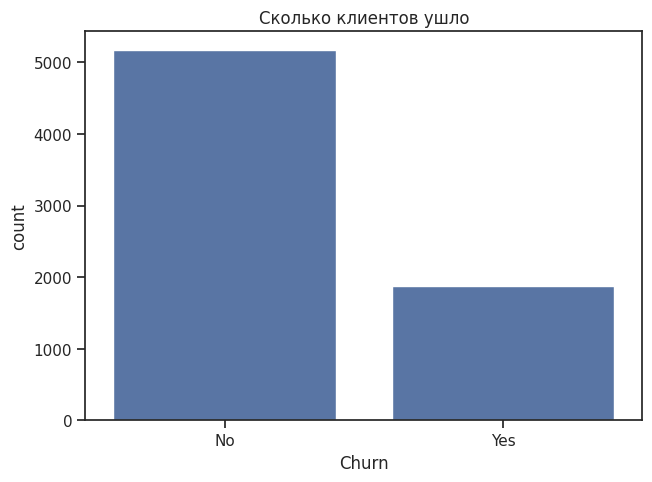

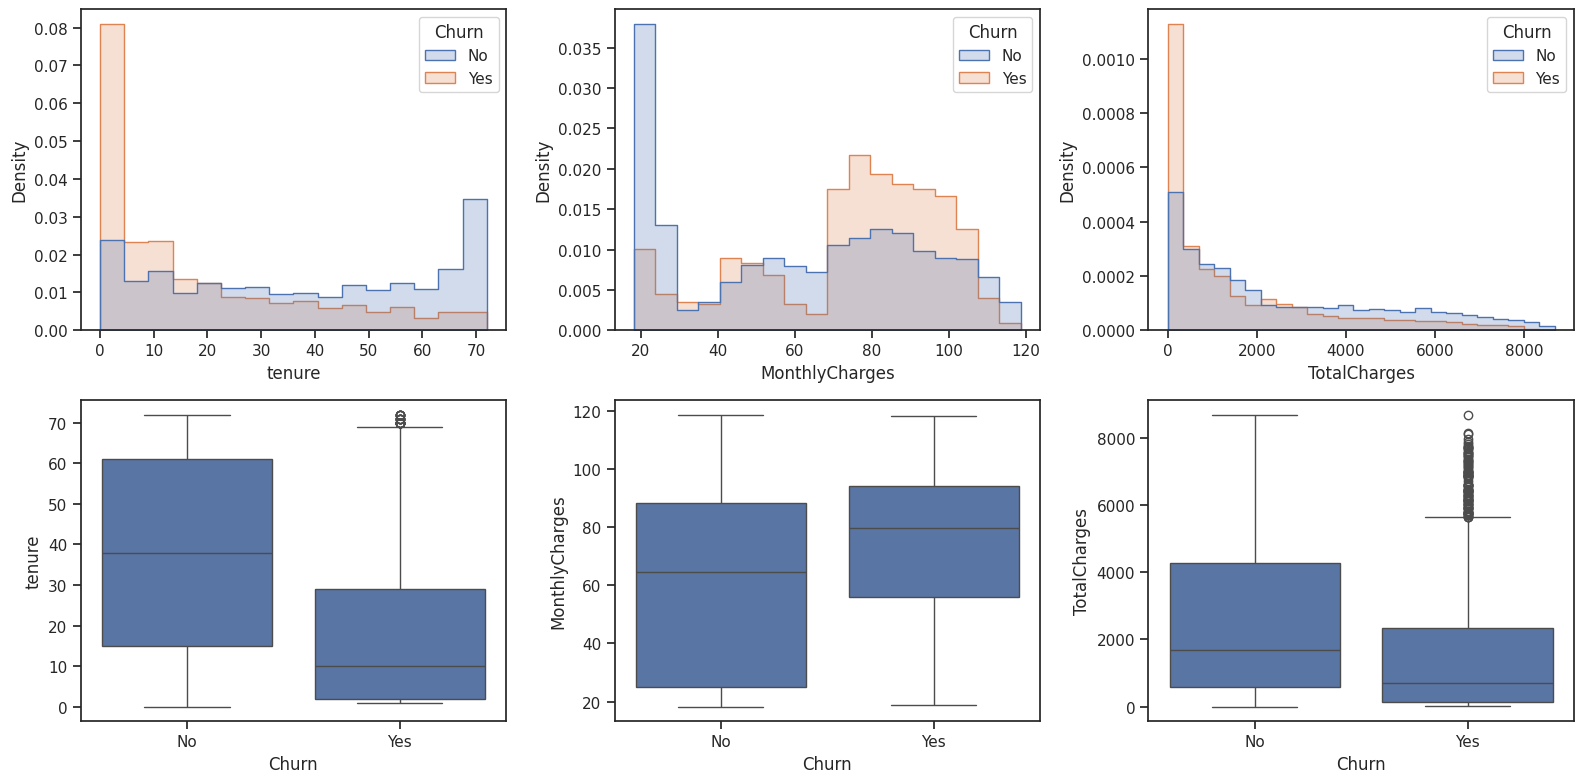

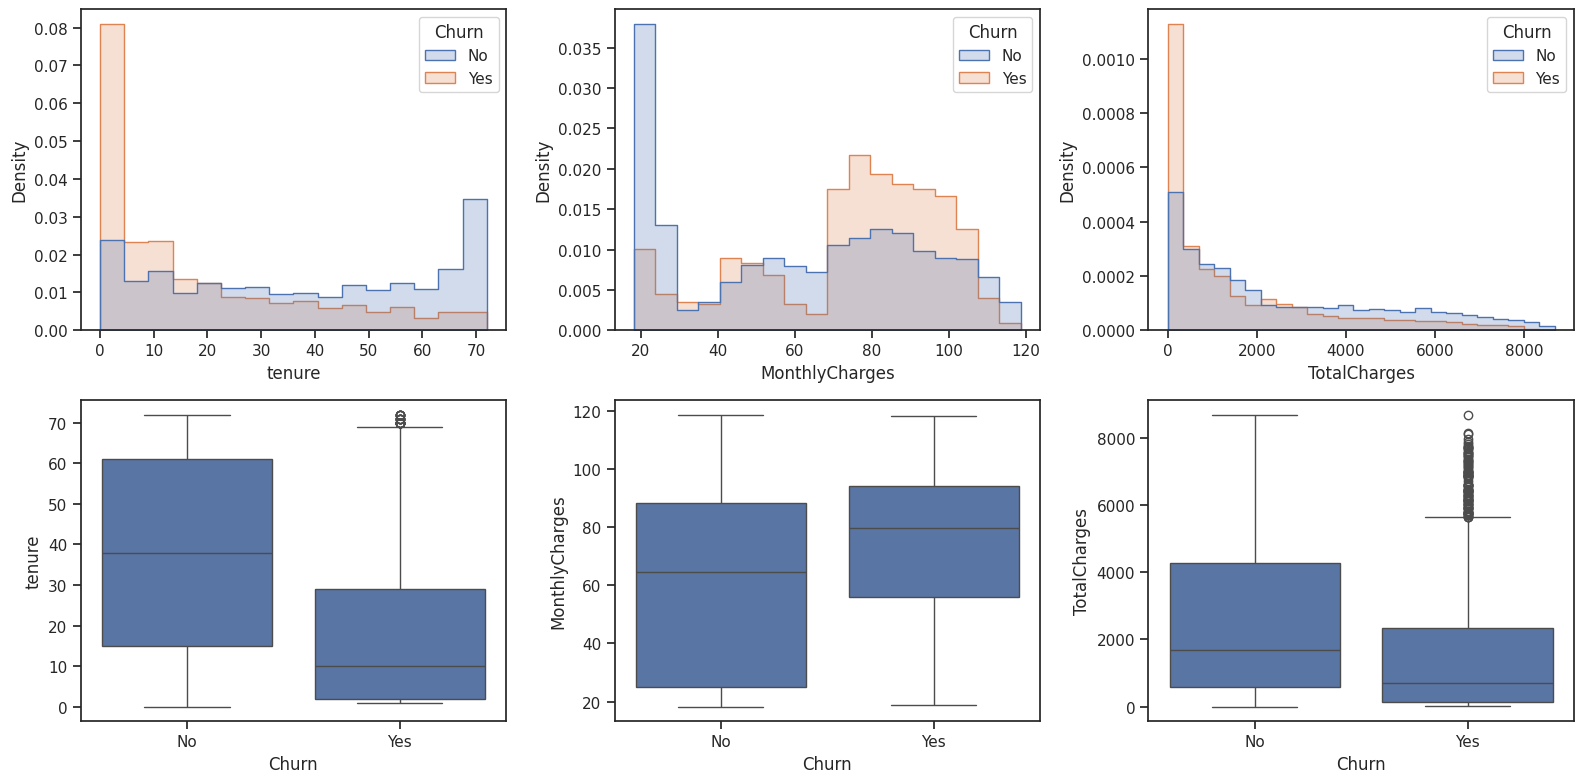

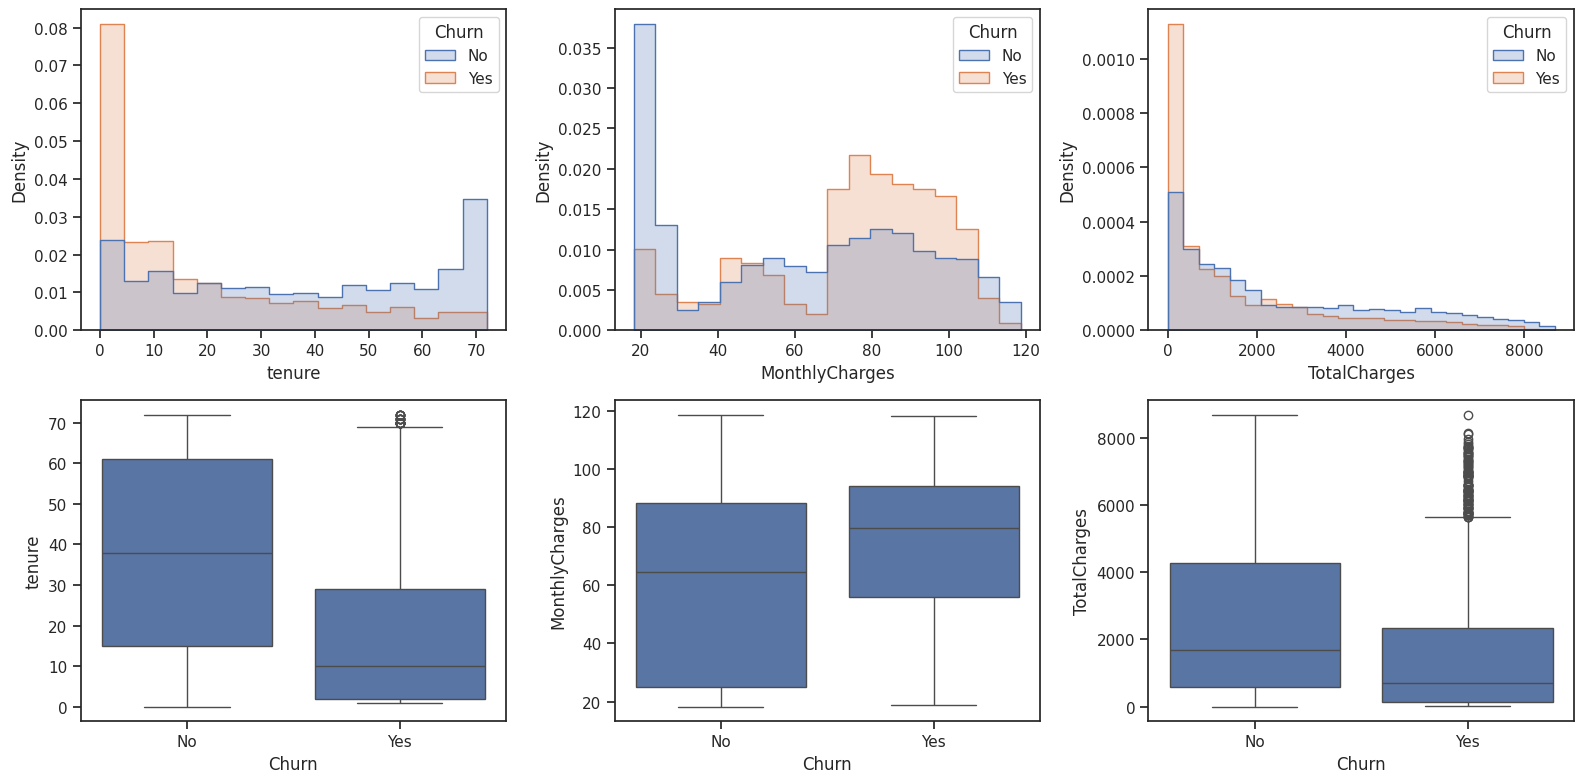

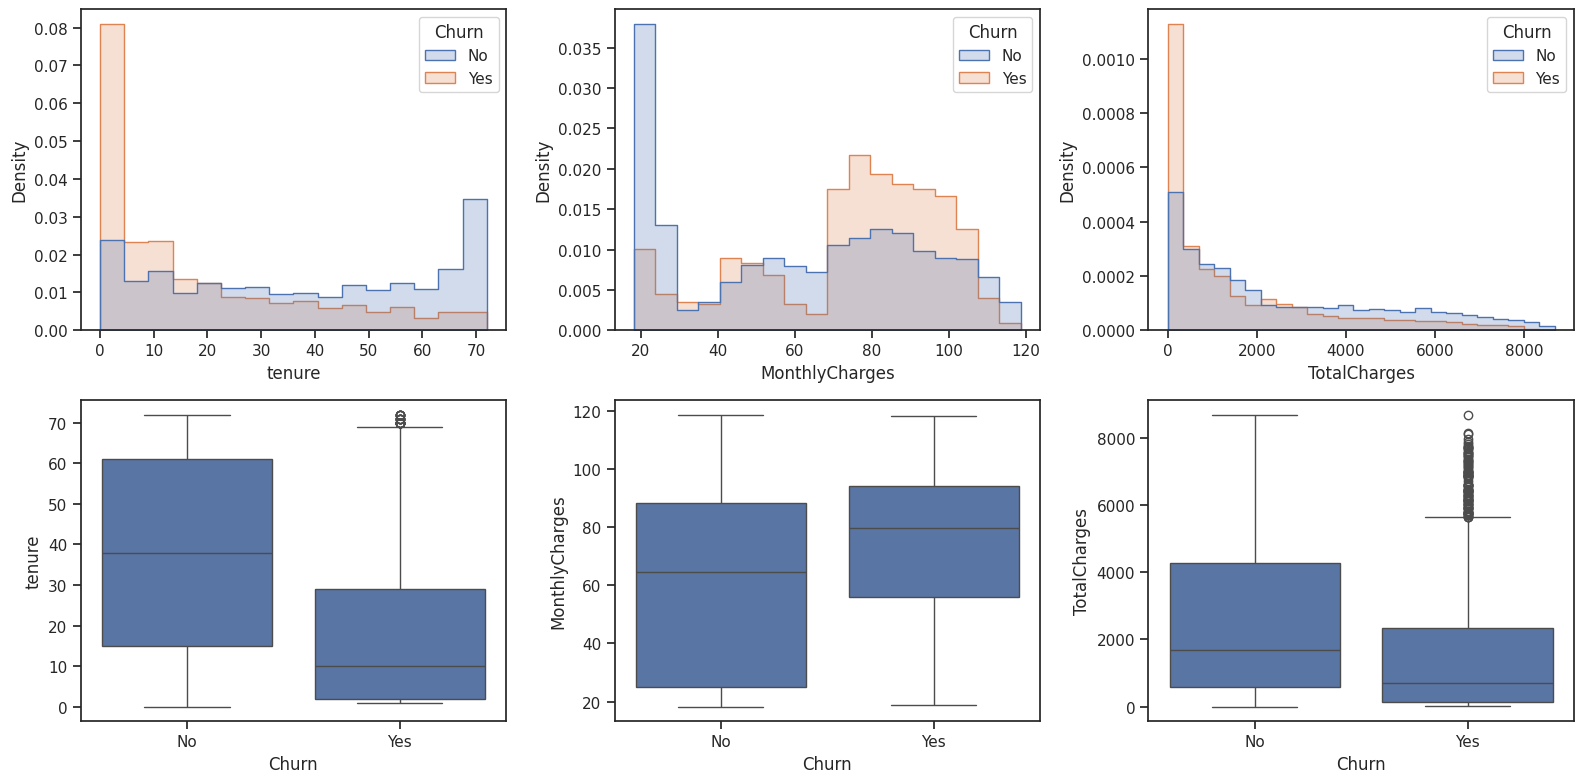

In [29]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, hue='Churn', stat='density', common_norm=False,
                 element='step', ax=axes[0, i])
    sns.boxplot(data=df, x='Churn', y=col, ax=axes[1, i])
plt.tight_layout()
plt.show()

In [30]:
df.groupby('Churn')[num_cols].median()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.425,1679.525
Yes,10.0,79.650,703.550


Что видно:

* ушедшие клиенты в основном «новички»: медианный срок жизни у них 10 месяцев против 38 у оставшихся;
* при этом ушедшие платят **больше** в месяц: медиана 80 против 64;
* `TotalCharges` у ушедших меньше, но это в основном следствие короткого `tenure`. Мы ещё вернёмся к этому в разделе про парадокс Симпсона.

### Категориальные признаки и отток

Для каждого категориального признака посчитаем долю ушедших в каждой категории и сравним со средней долей по всем клиентам (пунктир).

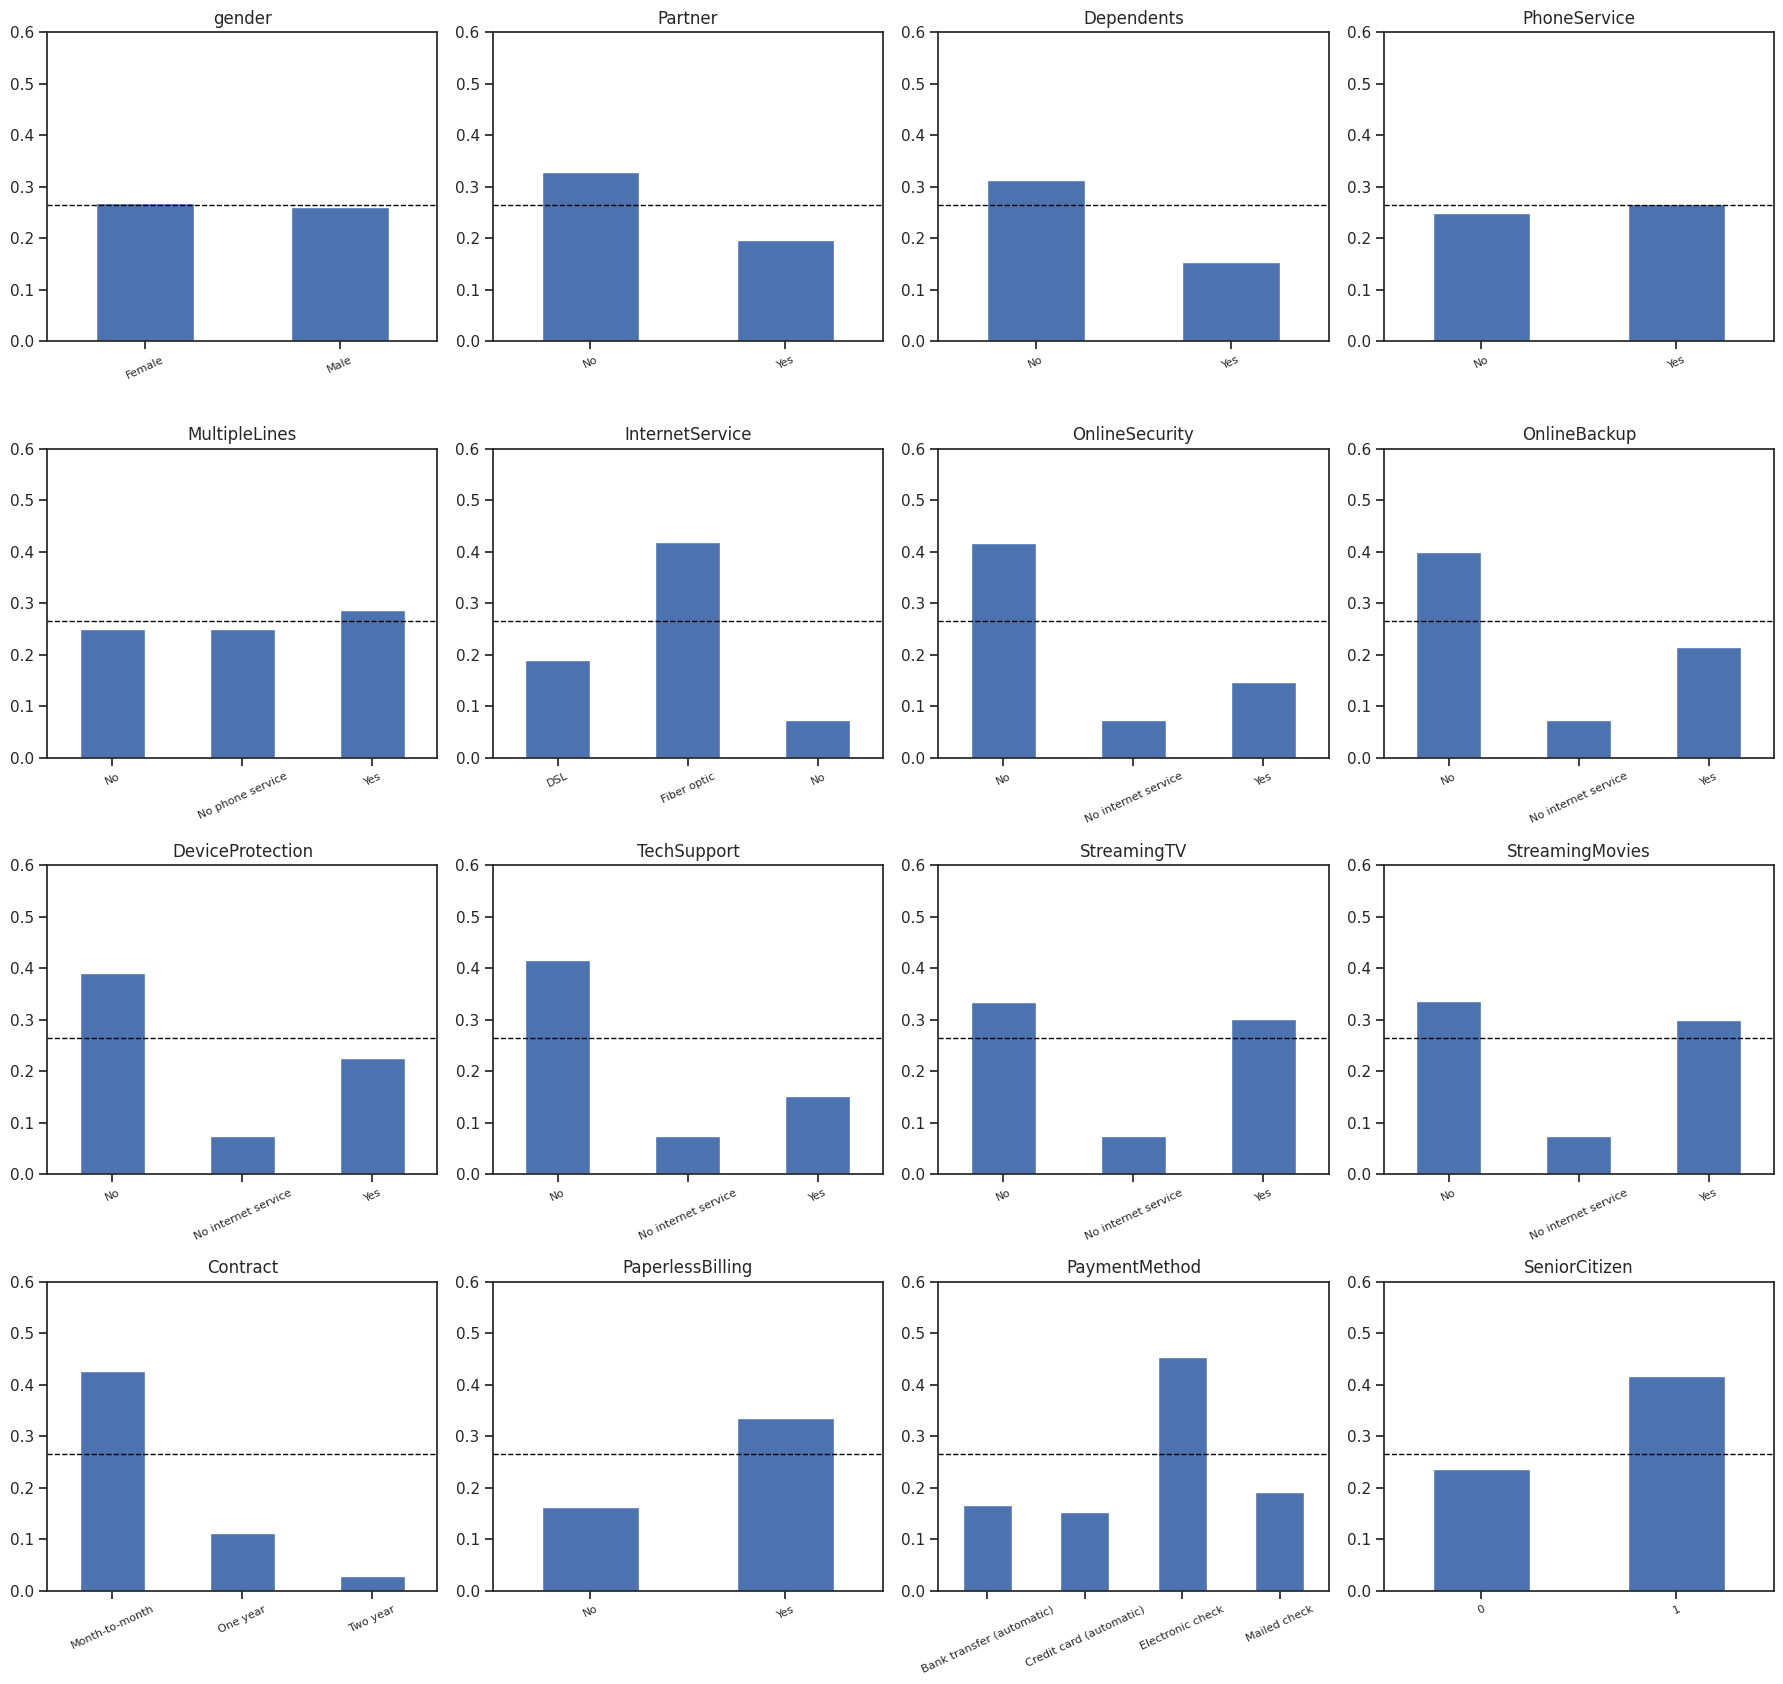

In [31]:
def churn_rate_by(col):
    """Доля ушедших клиентов в каждой категории признака col"""
    return df['Churn'].eq('Yes').groupby(df[col], observed=True).mean()


cat_cols = [c for c in df.columns
            if not pd.api.types.is_numeric_dtype(df[c]) and c != 'Churn'] + ['SeniorCitizen']

fig, axes = plt.subplots(4, 4, figsize=(18, 17))
for ax, col in zip(axes.flat, cat_cols):
    churn_rate_by(col).plot(kind='bar', ax=ax, rot=25)
    ax.axhline(churn_rate, color='black', linestyle='--', linewidth=1)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylim(0, 0.6)
    ax.tick_params(axis='x', labelsize=8)
plt.tight_layout()
plt.show()

Что видно:

* **тип контракта** выглядит самым сильным фактором: при помесячном контракте уходит 43% клиентов, при годовом 11%, при двухлетнем 3%;
* клиенты с **оптоволокном** (Fiber optic) уходят чаще: 42% против 19% у DSL;
* при оплате **электронным чеком** уходит 45% клиентов, при остальных способах 15–19%;
* клиенты **без** онлайн-защиты (`OnlineSecurity`) и техподдержки (`TechSupport`) уходят почти в 3 раза чаще, чем те, у кого эти услуги есть (около 42% против 15%);
* пенсионеры (`SeniorCitizen = 1`) уходят чаще: 42% против 24%;
* а вот **пол** и наличие **телефонной связи** почти ни на что не влияют: доля оттока практически совпадает со средней.

### Когорты по сроку жизни клиента

`tenure` удобно разбить на интервалы (когорты) и посмотреть отток в каждом из них. Так зависимость читается лучше, чем по гистограмме.

NameError: name 'churn_rate' is not defined

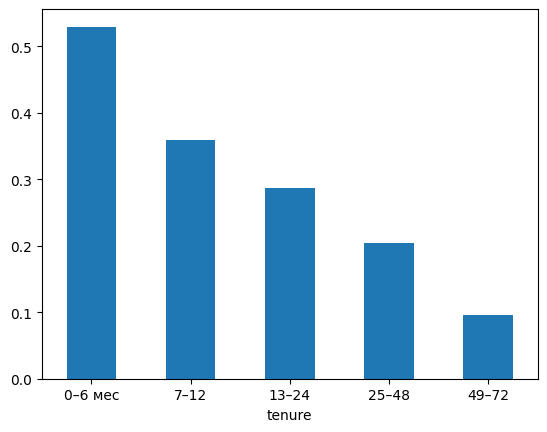

In [33]:
tenure_groups = pd.cut(df['tenure'], bins=[-1, 6, 12, 24, 48, 72],
                       labels=['0–6 мес', '7–12', '13–24', '25–48', '49–72'])

tenure_rates = df['Churn'].eq('Yes').groupby(tenure_groups, observed=True).mean()

tenure_rates.plot(kind='bar', rot=0)
plt.axhline(churn_rate, color='black', linestyle='--', linewidth=1)
plt.xlabel('срок жизни клиента, месяцев')
plt.ylabel('доля ушедших')
plt.title('Отток по когортам')
plt.show()

tenure_rates.round(3)

Больше половины (53%) клиентов, пришедших за последние полгода, уже ушли. Среди тех, кто с компанией больше 4 лет, отток около 10%. Самый опасный период для компании — первые месяцы.

### Взаимодействие двух признаков

Одномерный анализ не показывает, как признаки работают **вместе**. Посмотрим на отток сразу по двум признакам: типу контракта и интернет-сервису.

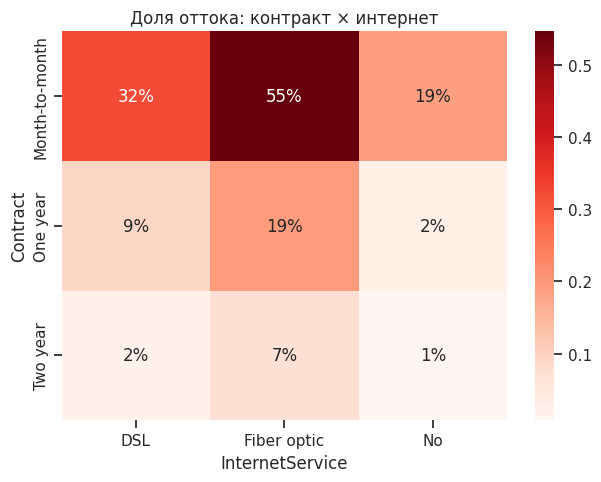

InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,1223,2128,524
One year,570,539,364
Two year,628,429,638


In [33]:
pivot = pd.crosstab(df['Contract'], df['InternetService'],
                    values=df['Churn'].eq('Yes'), aggfunc='mean')

sns.heatmap(pivot, annot=True, fmt='.0%', cmap='Reds')
plt.title('Доля оттока: контракт × интернет')
plt.show()

# Сколько клиентов в каждой клетке
pd.crosstab(df['Contract'], df['InternetService'])

Помесячный контракт + оптоволокно — самая рискованная комбинация: уходят 55% таких клиентов. И это большая группа (2128 человек, почти треть базы). А двухлетний контракт снижает отток даже у клиентов с оптоволокном, до 7%.

Всегда смотрите и на **размер клетки** (вторая таблица): высокий процент в группе из 10 человек мало что значит.

### Дублирующаяся информация в признаках

У шести признаков есть значение `No internet service`. Проверим, что это одни и те же клиенты.

In [34]:
internet_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                 'TechSupport', 'StreamingTV', 'StreamingMovies']
no_internet = df[internet_cols].eq('No internet service')

print('Клиентов с InternetService = No:', (df['InternetService'] == 'No').sum())
print('Строк, где все 6 признаков = No internet service:', no_internet.all(axis=1).sum())
print('Строк, где хотя бы один из 6 = No internet service:', no_internet.any(axis=1).sum())

Клиентов с InternetService = No: 1526
Строк, где все 6 признаков = No internet service: 1526
Строк, где хотя бы один из 6 = No internet service: 1526


Это одни и те же 1526 клиентов. Значит, категория `No internet service` в шести колонках повторяет информацию из `InternetService = No`.

Это не ошибка, но при подготовке признаков для модели такое значение можно заменить на `No`: информация об отсутствии интернета всё равно сохранится в `InternetService`. Так же `No phone service` в `MultipleLines` повторяет `PhoneService = No`.

### Признак, который почти выводится из других

`TotalCharges` — это сумма всех платежей клиента. Кажется, она должна быть примерно равна `tenure × MonthlyCharges`. Проверим.

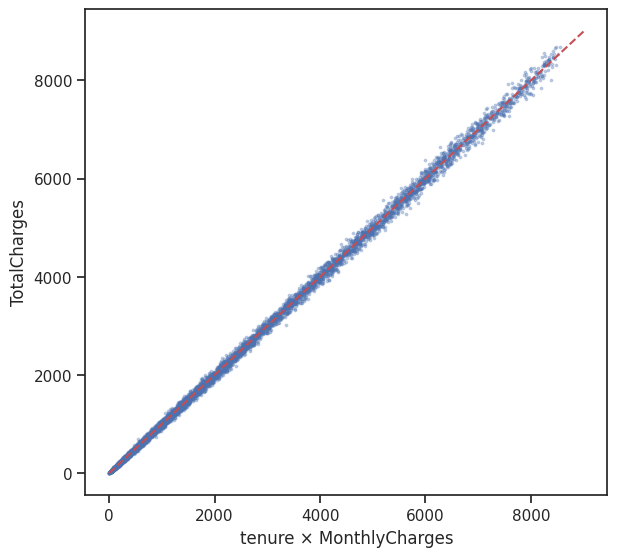

Корреляция: 0.9996


In [35]:
estimate = df['tenure'] * df['MonthlyCharges']

plt.figure(figsize=(6, 6))
plt.scatter(estimate, df['TotalCharges'], s=3, alpha=0.3)
plt.plot([0, 9000], [0, 9000], 'r--')
plt.xlabel('tenure × MonthlyCharges')
plt.ylabel('TotalCharges')
plt.show()

print('Корреляция:', np.corrcoef(estimate, df['TotalCharges'])[0, 1].round(4))

Корреляция 0.9996: `TotalCharges` почти полностью определяется двумя другими признаками. Небольшие отклонения от прямой появляются, скорее всего, потому, что тариф клиента мог меняться со временем.

Для линейных моделей такие почти дублирующие признаки создают проблему **мультиколлинеарности**, к ней мы ещё вернёмся.

## Взаимозависимость в данных

### Сначала картинка, потом число: квартет Энскомба

Коэффициенты корреляции удобны, но одно число не описывает данные полностью. Классический пример — **квартет Энскомба**: четыре набора точек с почти одинаковыми средними, дисперсиями и корреляцией (≈ 0.82), но совершенно разной структурой.

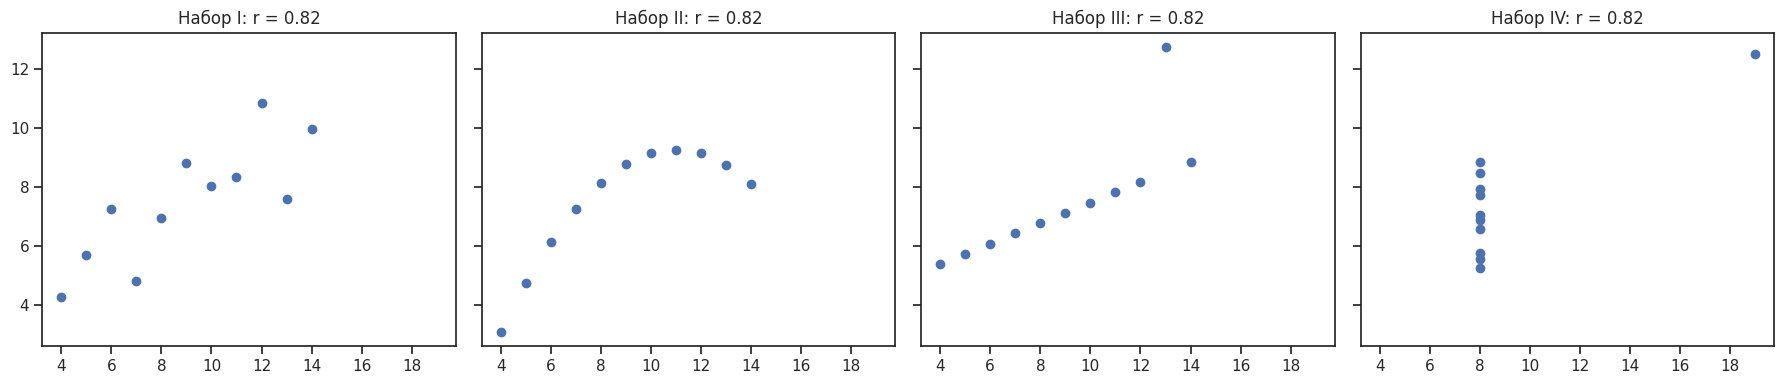

In [36]:
x = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
anscombe = {
    'I':   (x, [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    'II':  (x, [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    'III': (x, [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    'IV':  ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8],
            [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharex=True, sharey=True)
for ax, (name, (xs, ys)) in zip(axes, anscombe.items()):
    r = np.corrcoef(xs, ys)[0, 1]
    ax.scatter(xs, ys)
    ax.set_title(f'Набор {name}: r = {r:.2f}')
plt.tight_layout()
plt.show()

Только в первом наборе связь похожа на линейную с шумом. Во втором связь нелинейная, в третьем всё портит один выброс, а в четвёртом «корреляцию» создаёт одна-единственная точка.

**Вывод:** прежде чем считать корреляцию, посмотрите на scatter plot.

### 1. Корреляция

**Корреляция Пирсона**

pearson.svg

Корреляция Пирсона — это мера **линейной** взаимосвязи двух числовых столбцов.

* $r$	=	correlation coefficient
* $x_{i}$	=	values of the x-variable in a sample
* $\bar{x}$	=	mean of the values of the x-variable
* $y_{i}$	=	values of the y-variable in a sample
* $\bar{y}$	=	mean of the values of the y-variable

Значения лежат от -1 до 1: 1 — точная возрастающая линейная связь, -1 — точная убывающая, 0 — линейной связи нет (но нелинейная при этом вполне может быть, вспомните квартет Энскомба).

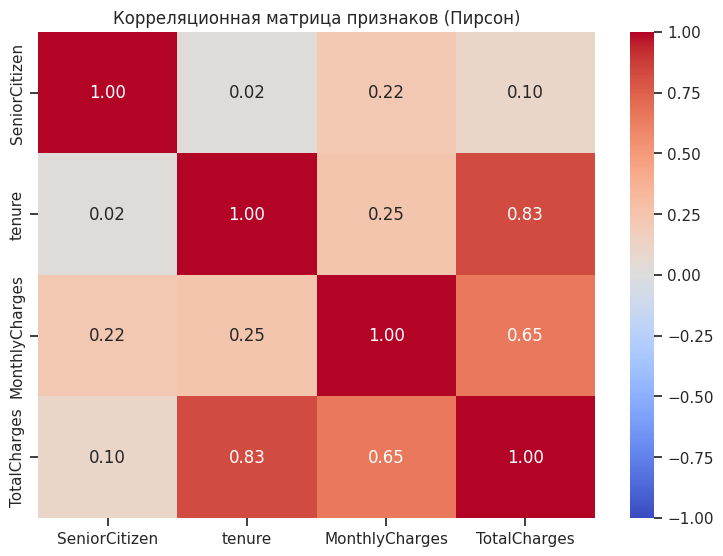

In [37]:
corr = df.corr(numeric_only=True)  # матрица корреляций

plt.figure(figsize=(8, 6))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, annot=True, fmt='.2f')
plt.title("Корреляционная матрица признаков (Пирсон)")
plt.show()

**Корреляция Спирмена**

Коэффициент корреляции Спирмена основан на ранжировании значений переменных и измеряет степень монотонной связи между ними.

Значение коэффициента корреляции Спирмена лежит в диапазоне от -1 до 1. Значение -1 означает полную отрицательную связь (чем больше одна переменная, тем меньше другая), значение 1 означает положительную связь (чем больше одна переменная, тем больше другая), а значение 0 означает отсутствие связи между переменными.

Можно использовать для порядковых переменных!

spearman.svg

* $\rho$	=	Spearman's rank correlation coefficient
* $d_{i}$	=	difference between the two ranks of each observation
* $n$	=	number of observations

[Пример расчета коэффициента корреляции Спирмена](https://statpsy.ru/spearman/primer-raschet-spearman/)

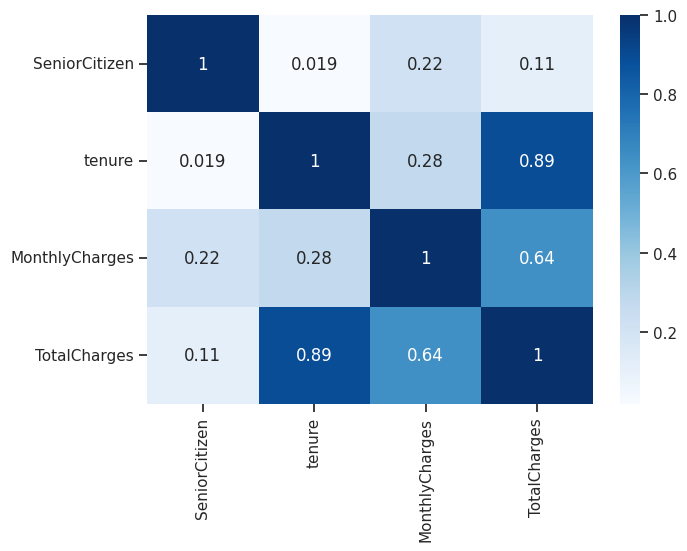

In [38]:
corr = df.corr(method='spearman', numeric_only=True)

sns.heatmap(corr, cmap="Blues", annot=True);

**Корреляция Кендалла**

Как и корреляция Спирмена, основана на **рангах** и измеряет монотонную связь. Поэтому подходит для числовых и порядковых признаков. Для номинальных категорий, у которых нет естественного порядка (например, способ оплаты), она смысла не имеет.

Идея простая: берём все пары объектов и смотрим, согласованы ли они. Пара согласована, если у того объекта, у которого больше $x$, больше и $y$. Коэффициент Кендалла — это доля согласованных пар минус доля несогласованных.

На практике Кендалл и Спирмен обычно дают похожие выводы. Кендалл устойчивее на маленьких выборках и когда много одинаковых значений.

Вычислим матрицу корреляций, используя корреляцию Кендалла.

Сравните её с матрицами Пирсона и Спирмена. Для какой пары признаков коэффициенты отличаются сильнее всего? Как вы думаете, почему?

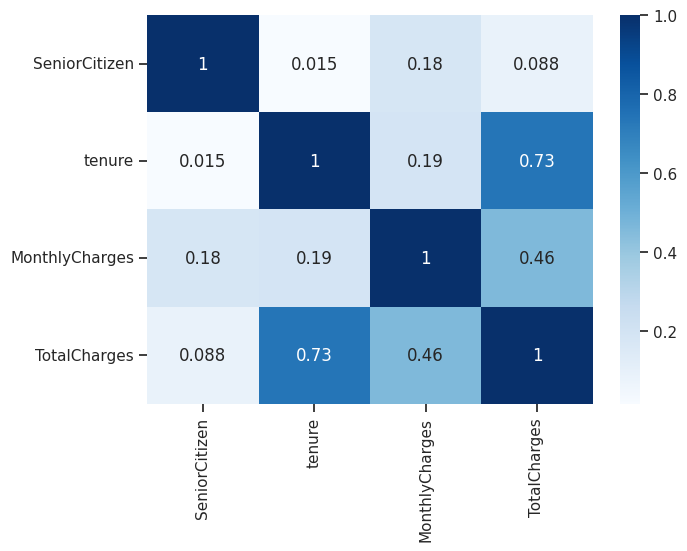

In [39]:
# your code here

corr = df.corr(method='kendall', numeric_only=True)

sns.heatmap(corr, cmap="Blues", annot=True);

### 2. V-мера Крамера

*Для измерения связи между Категориальным - Категориальным признаком*

Для оценки степени взаимосвязи категориальных столбцов можно вычислять V-меру Крамера.
Это вариант нормировки статистики $\chi^2$. Статистика $\chi^2$ - это функция, измеряющая меру взаимосвязи двух категориальных переменных.

Пусть $X, Y$ - две категориальных переменных, тогда $\chi^2$ вычисляется по формуле

$$\chi^2(X,Y)=\sum_{i,j}\frac{(O_{ij}-E_{ij})^2}{E_{ij}},$$

где $O_{ij}$ - наблюдаемая частота события, $E_{ij}$ - ожидаемая частота события (в предположении, что величины $X$ и $Y$ независимы).

Чем больше значение $\chi^2$, тем сильнее данные отличаются от ситуации, когда переменные независимы.



**Покажем на примере.**

Изучим по некоторым данным зависимость факта курения и повышенного давления. По данным составим таблицу сопряженности.

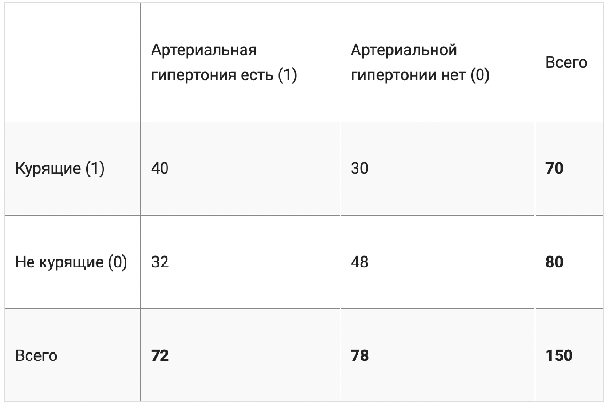

Вычисляем $\chi^2$:

$O_{11} = 40$

$E_{11} = 70 * 72 / 150 \approx 33.6 $ (так считается $E_{ij}$, если величины независимы)

Аналогично вычисляются оставшиеся слагаемые в формуле. Получаем

$\chi^2(X,Y) = (40-33.6)^2/33.6 + (30-36.4)^2/36.4 + (32-38.4)^2/38.4 + (48-41.6)^2/41.6 = 4.396$



Чем больше $\chi^2$, тем сильнее наблюдаемые частоты отличаются от ожидаемых при независимости.

В случае, если признаки независимы, то ожидаемая и наблюдаемая частоты совпадут, и $\chi^2=0$.



Но у $\chi^2$ есть недостаток: он растёт вместе с размером выборки. Если взять те же пропорции, но в 10 раз больше людей, $\chi^2$ станет в 10 раз больше, хотя связь сильнее не стала. Поэтому сам по себе $\chi^2$ плохо подходит как мера силы связи.

V-мера Крамера - это нормировка $\chi^2$ на число наблюдений $n$ и на число категорий:

$$V = \sqrt{\frac{\chi^2/n}{min(k-1,r-1)}},$$

где


$n$ - общее число наблюдений

$k$ - число категорий в $X$

$r$ - число категорий в $Y$


В результате этой нормировки V-мера находится на отрезке от 0 до 1 и легко интерпретируется: *чем больше V-мера - тем больше зависимость между двумя переменными, и наоборот.*

Для примера с курением: $V = \sqrt{4.396 / 150} \approx 0.17$, то есть связь слабая.

In [40]:
!pip install association-metrics -q

  Preparing metadata (setup.py) ... done


In [41]:
import association_metrics as am

# Переводим все нечисловые столбцы в тип category: association_metrics работает только с ним.
# Проверяем через is_numeric_dtype, а не dtype == 'object': в pandas 3 строки имеют тип str.
df_cat = df.apply(lambda x: x if pd.api.types.is_numeric_dtype(x) else x.astype("category"))

cramersv = am.CramersV(df_cat)

cramersv.fit()

,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
gender,1.000000,0.001808,0.010517,0.006488,0.009452,0.011320,0.017025,0.013798,0.006029,0.009722,0.008844,0.010641,0.008153,0.011754,0.018646,0.008612
Partner,0.001808,1.000000,0.452676,0.017706,0.143898,0.000907,0.152010,0.153337,0.166568,0.127642,0.137343,0.129574,0.296039,0.014877,0.162762,0.150448
Dependents,0.010517,0.452676,1.000000,0.001762,0.025094,0.180267,0.194579,0.162760,0.157570,0.182377,0.147082,0.141335,0.244212,0.111377,0.150744,0.164221
PhoneService,0.006488,0.017706,0.001762,1.000000,1.000000,0.452425,0.176272,0.172818,0.172317,0.176977,0.180434,0.177520,0.003976,0.016505,0.010297,0.011942
MultipleLines,0.009452,0.143898,0.025094,1.000000,1.000000,0.396726,0.229608,0.245163,0.246342,0.230162,0.261791,0.262356,0.080408,0.166341,0.166930,0.040109
InternetService,0.011320,0.000907,0.180267,0.452425,0.396726,1.000000,0.724466,0.707184,0.707108,0.722904,0.717099,0.716008,0.206921,0.378427,0.313123,0.322455
OnlineSecurity,0.017025,0.152010,0.194579,0.176272,0.229608,0.724466,1.000000,0.718434,0.717291,0.733071,0.707788,0.708208,0.301349,0.341800,0.304959,0.347400
OnlineBackup,0.013798,0.153337,0.162760,0.172818,0.245163,0.707184,0.718434,1.000000,0.719125,0.719834,0.714699,0.713682,0.258572,0.321046,0.282517,0.292316
DeviceProtection,0.006029,0.166568,0.157570,0.172317,0.246342,0.707108,0.717291,0.719125,1.000000,0.726485,0.733661,0.736047,0.296976,0.321631,0.287021,0.281580
TechSupport,0.009722,0.127642,0.182377,0.176977,0.230162,0.722904,0.733071,0.719834,0.726485,1.000000,0.716266,0.716327,0.331021,0.329524,0.306888,0.342916


## Причём здесь статистика? Интуиция статистических тестов

Мы уже видели, что доля оттока различается между группами. Например, у мужчин она 26.2%, у женщин 26.9%. Отличие есть, но настоящее ли оно? Может быть, это просто случайность?

Представьте, что вы подбросили монетку 10 раз и получили 6 орлов. Значит ли это, что монетка «нечестная»? Скорее всего нет: при 10 бросках 6 орлов выпадают постоянно, просто случайно. А вот 1000 орлов из 1000 бросков — уже очень подозрительно.

**Статистический тест** отвечает ровно на такой вопрос: *могла ли наблюдаемая разница появиться просто случайно, если на самом деле никакой связи нет?*

### Тест перемешиванием

Самый понятный способ ответить на этот вопрос — проверить экспериментом.

1. Допустим, что пол на отток никак не влияет. Тогда метки «ушёл / остался» распределены между мужчинами и женщинами случайно.
2. Перемешаем столбец `Churn` случайным образом. Так мы точно разрушим любую связь с полом.
3. Посчитаем разницу в доле оттока между мужчинами и женщинами на перемешанных данных.
4. Повторим 1000 раз. Получим, какие разницы бывают **просто случайно**.
5. Сравним их с разницей на настоящих данных.

Сделаем то же самое для признака `Partner` (есть ли у клиента партнёр).

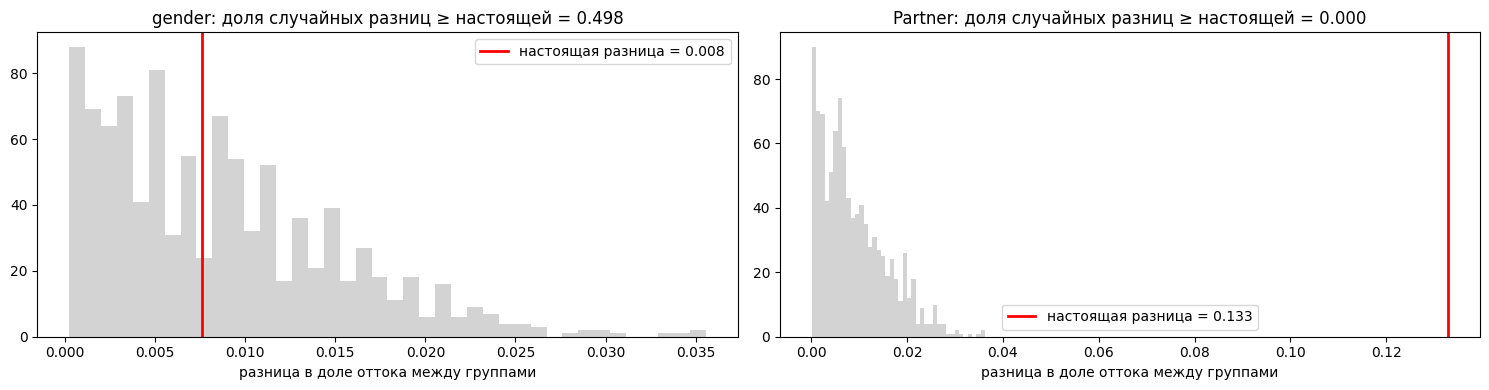

In [13]:
from matplotlib import pyplot as plt
import numpy as np

def permutation_test(col, n_iter=1000, seed=0):
    """Тест перемешиванием: связан ли бинарный признак col с оттоком"""
    rng = np.random.default_rng(seed)
    churn = df['Churn'].eq('Yes').to_numpy()
    groups = df[col].to_numpy()
    a, b = np.unique(groups)

    def diff(y):
        return abs(y[groups == a].mean() - y[groups == b].mean())

    observed = diff(churn)
    random_diffs = np.array([diff(rng.permutation(churn)) for _ in range(n_iter)])
    share = (random_diffs >= observed).mean()
    return observed, random_diffs, share


fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, col in zip(axes, ['gender', 'Partner']):
    observed, random_diffs, share = permutation_test(col)
    ax.hist(random_diffs, bins=40, color='lightgray')
    ax.axvline(observed, color='red', linewidth=2, label=f'настоящая разница = {observed:.3f}')
    ax.set_title(f'{col}: доля случайных разниц ≥ настоящей = {share:.3f}')
    ax.set_xlabel('разница в доле оттока между группами')
    ax.legend()
plt.tight_layout()
plt.show()

Серым показаны разницы, которые получаются случайно, когда связи точно нет. Красная линия — разница на настоящих данных.

* **Пол.** Настоящая разница (0.008) спокойно лежит внутри серой «горки»: примерно в половине перемешиваний разница выходила не меньше. Значит, она вполне может быть случайной.
* **Наличие партнёра.** Настоящая разница (0.13) лежит далеко правее всего серого: ни одно из 1000 перемешиваний такой разницы не дало. Объяснить её случайностью очень трудно.

Доля случайных разниц, которые не меньше настоящей, и называется **p-value**. Простыми словами: *насколько часто такое бывает случайно, если связи на самом деле нет*.

* **маленькое p-value** → «вряд ли это случайность, связь, скорее всего, есть». Маленьким договорились считать p-value меньше 0.05, то есть реже 1 раза из 20;
* **большое p-value** → «такое легко получается случайно, данных недостаточно, чтобы утверждать, что связь есть».

Порог 0.05 — просто договорённость, а не закон природы.

Все статистические тесты (χ², ANOVA и другие) устроены так же. Разница только в том, что вместо 1000 перемешиваний они используют готовую формулу, которая сразу говорит, какие значения бывают случайно.

### «Значимо» не значит «сильно»

Чем больше данных, тем легче тесту заметить даже крошечную разницу. Представьте, что вы сравниваете рост учеников двух школ, и в одной ученики в среднем на 2 мм выше. Если измерить по 10 человек, тест скажет «может быть случайностью». Если по миллиону человек, тест скажет «точно не случайность». Но 2 мм от этого важнее не станут.

Поэтому всегда смотрим на две вещи:

1. **Не случайность ли это?** — p-value.
2. **Насколько разница большая?** — сама разница (в процентах, рублях, месяцах) или нормированная мера вроде V Крамера.

### Насколько мы уверены в цифре? Бутстрэп

Мы посчитали, что при помесячном контракте уходит 42.7% клиентов. Но если бы у нас была другая выборка клиентов, цифра была бы немного другой. Насколько другой?

Трюк под названием **бутстрэп**: сделаем много «новых выборок» из имеющейся. Для этого вытаскиваем клиентов случайно с возвращением (одного и того же клиента можно вытащить несколько раз) и смотрим, как скачет доля оттока. Диапазон, в который попадают 95% таких значений, называют **доверительным интервалом**.

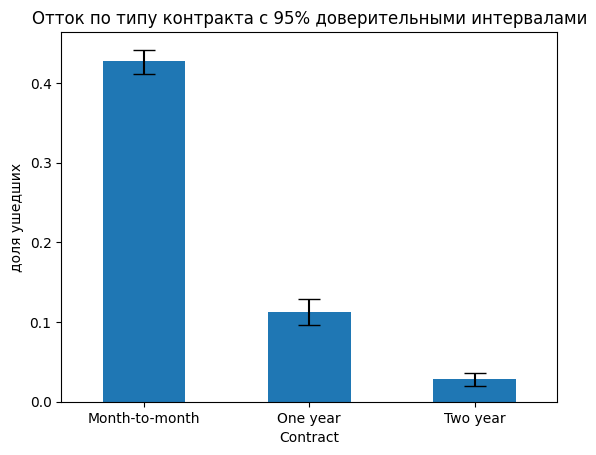

,доля оттока,нижняя граница,верхняя граница
Contract,,,
Month-to-month,0.427,0.411,0.442
One year,0.113,0.096,0.128
Two year,0.028,0.020,0.037


In [14]:
rng = np.random.default_rng(0)
rows = []
for contract, group in df.groupby('Contract'):
    churn = group['Churn'].eq('Yes').to_numpy()
    boot = [rng.choice(churn, size=len(churn)).mean() for _ in range(1000)]
    low, high = np.percentile(boot, [2.5, 97.5])
    rows.append({'Contract': contract, 'доля оттока': churn.mean(),
                 'нижняя граница': low, 'верхняя граница': high})
ci = pd.DataFrame(rows).set_index('Contract')

errors = [ci['доля оттока'] - ci['нижняя граница'], ci['верхняя граница'] - ci['доля оттока']]
ci['доля оттока'].plot(kind='bar', yerr=errors, capsize=8, rot=0)
plt.ylabel('доля ушедших')
plt.title('Отток по типу контракта с 95% доверительными интервалами')
plt.show()

ci.round(3)

Интервалы узкие и не пересекаются: разница между типами контрактов точно не случайна. Если бы интервалы двух групп сильно перекрывались, делать вывод о разнице было бы рано.

### 3. ANOVA

*Для измерения связи между числовым и категориальным признаком*

ANOVA (Analysis of Variance, дисперсионный анализ) отвечает на вопрос: отличаются ли средние значения числового признака в разных группах? Например, отличается ли средний `MonthlyCharges` у клиентов с разными типами интернета?

Интуиция: сравниваем два разброса.

* **Разброс между группами** — насколько далеко друг от друга средние групп.
* **Разброс внутри групп** — насколько сильно отличаются друг от друга клиенты внутри одной группы.

Если средние групп отличаются гораздо сильнее, чем клиенты внутри групп, значит, группа действительно влияет на признак. Отношение этих двух разбросов называется **F-статистикой**. А p-value, как и в тесте перемешиванием, показывает, могло ли такое отношение получиться случайно.

ANOVA предполагает, что внутри каждой группы признак распределён примерно нормально, а разброс в группах похож. У нас это выполняется не всегда (например, `TotalCharges` сильно скошен вправо). Если сомневаетесь, есть ранговый аналог — тест Краскела–Уоллиса (`scipy.stats.kruskal`). Он относится к ANOVA так же, как Спирмен к Пирсону.

In [15]:
# Игрушечный пример: цена машины в зависимости от типа топлива
ColumnNames = ['FuelType', 'CarPrice']
DataValues = [
    ['Petrol', 2000], ['Petrol', 2100], ['Petrol', 1900], ['Petrol', 2150],
    ['Petrol', 2100], ['Petrol', 2200], ['Petrol', 1950],
    ['Diesel', 2500], ['Diesel', 2700], ['Diesel', 2900], ['Diesel', 2850],
    ['Diesel', 2600], ['Diesel', 2500], ['Diesel', 2700],
    ['CNG', 1500], ['CNG', 1400], ['CNG', 1600], ['CNG', 1650],
    ['CNG', 1600], ['CNG', 1500], ['CNG', 1500],
]
CarData = pd.DataFrame(data=DataValues, columns=ColumnNames)

from scipy.stats import f_oneway

# Исходное предположение: тип топлива на цену НЕ влияет,
# а различия средних между группами случайны.
# f_oneway принимает значения каждой группы и возвращает F-статистику и p-value.
CategoryGroupLists = CarData.groupby('FuelType')['CarPrice'].apply(list)
AnovaResults = f_oneway(*CategoryGroupLists)

print('p-value:', AnovaResults.pvalue)

if AnovaResults.pvalue >= 0.05:
    print('Различия средних цен вполне могли получиться случайно')
else:
    print('Средние цены в группах различаются, и это вряд ли случайность')

p-value: 4.3558466424602e-12
Средние цены в группах различаются, и это вряд ли случайность


In [16]:
Data = []

for c1 in df.columns:
    for c2 in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c1]) and pd.api.types.is_numeric_dtype(df[c2]):
            CategoryGroupLists = df.groupby(c1)[c2].apply(list)
            p_value = f_oneway(*CategoryGroupLists).pvalue

            # eta² — доля разброса c2, которую объясняет разбиение на группы по c1 (от 0 до 1)
            group_means = df.groupby(c1)[c2].transform('mean')
            eta2 = ((group_means - df[c2].mean()) ** 2).sum() / ((df[c2] - df[c2].mean()) ** 2).sum()

            Data.append({'Category': c1, 'Numerical': c2, 'p-value': p_value,
                         'Различия значимы': p_value < 0.05, 'eta²': eta2})

AnovaRes = pd.DataFrame(Data).sort_values('eta²', ascending=False)
AnovaRes.round(4)

,Category,Numerical,p-value,Различия значимы,eta²
0,customerID,SeniorCitizen,NaN,False,1.0000
1,customerID,tenure,NaN,False,1.0000
2,customerID,MonthlyCharges,NaN,False,1.0000
49,TotalCharges,tenure,0.0000,True,0.9930
50,TotalCharges,MonthlyCharges,0.0000,True,0.9717
48,TotalCharges,SeniorCitizen,0.0000,True,0.9514
20,InternetService,MonthlyCharges,0.0000,True,0.8207
35,StreamingTV,MonthlyCharges,0.0000,True,0.7009
38,StreamingMovies,MonthlyCharges,0.0000,True,0.6979
29,DeviceProtection,MonthlyCharges,0.0000,True,0.6261


Клиентов у нас около 7000, поэтому «значимыми» оказываются многие пары, даже где разница крошечная (вспомните пример про 2 мм). Поэтому таблица отсортирована по **eta²** — доле разброса числового признака, которую объясняет деление на группы (отношение разброса между группами к разбросу внутри групп). Это и есть ответ на вопрос «насколько сильно».

Например, тип интернета объясняет большую часть разброса `MonthlyCharges` (логично: оптоволокно дороже), а пол почти ничего не объясняет.

## $\phi_k$

$\phi_k$ - коэффициент корреляции, который можно вычислять для всех типов признаков. Он основан на вычислении статистики $\chi^2$.

Если говорить грубо, то для категориальных признаков мы просто считаем $\chi^2$, а для числовых - сначала бинаризуем признаки (то есть разбиваем на несколько интервалов значений), а затем также вычисляем $\chi^2$.

В реальности подход чуть сложнее - о нем можно почитать в авторской [статье](https://arxiv.org/abs/1811.11440).


In [19]:
!pip install phik -q

In [20]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


interval columns not set, guessing: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


<Axes: >

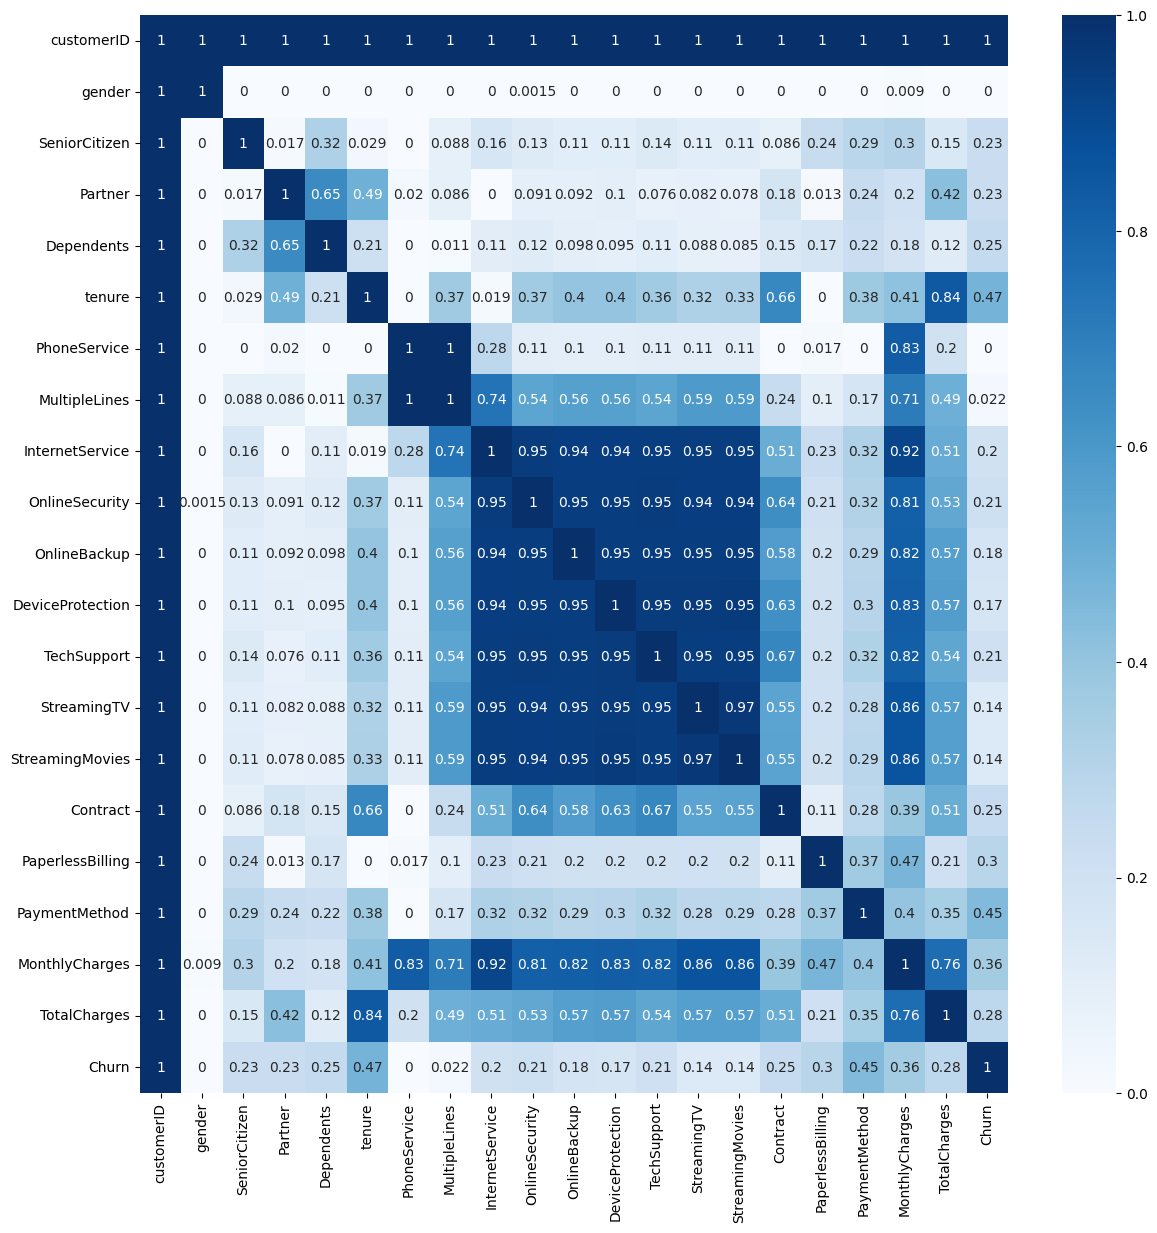

In [30]:
import phik

plt.figure(figsize=(14,14))

ph = df.phik_matrix()

sns.heatmap(ph, cmap="Blues", annot=True)

In [31]:
ph.style.background_gradient(cmap='coolwarm')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
customerID,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
gender,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001460,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.009025,0.000000,0.000000
SeniorCitizen,1.000000,0.000000,1.000000,0.016992,0.324576,0.028663,0.000000,0.087925,0.160702,0.127319,0.109995,0.110177,0.135283,0.111714,0.113778,0.086231,0.242133,0.292725,0.304691,0.149384,0.233432
Partner,1.000000,0.000000,0.016992,1.000000,0.652122,0.491658,0.019540,0.086249,0.000000,0.091202,0.092012,0.100092,0.076326,0.082251,0.077506,0.179736,0.013218,0.243008,0.203237,0.424467,0.232930
Dependents,1.000000,0.000000,0.324576,0.652122,1.000000,0.212209,0.000000,0.011198,0.108463,0.117219,0.097766,0.094597,0.109753,0.088193,0.084684,0.147680,0.172593,0.224903,0.184213,0.119077,0.253936
tenure,1.000000,0.000000,0.028663,0.491658,0.212209,1.000000,0.000000,0.374604,0.019357,0.365936,0.401085,0.401463,0.363817,0.321011,0.331299,0.664660,0.000000,0.375115,0.411002,0.842146,0.474001
PhoneService,1.000000,0.000000,0.000000,0.019540,0.000000,0.000000,1.000000,1.000000,0.278954,0.106021,0.103910,0.103604,0.106451,0.108565,0.106784,0.000000,0.016811,0.000000,0.831362,0.198660,0.000000
MultipleLines,1.000000,0.000000,0.087925,0.086249,0.011198,0.374604,1.000000,1.000000,0.739808,0.540261,0.562933,0.564610,0.541088,0.586049,0.586815,0.244410,0.099953,0.174849,0.710101,0.493936,0.021922
InternetService,1.000000,0.000000,0.160702,0.000000,0.108463,0.019357,0.278954,0.739808,1.000000,0.949498,0.942842,0.942811,0.948914,0.946713,0.946294,0.505187,0.231438,0.323886,0.918980,0.508222,0.196202
OnlineSecurity,1.000000,0.001460,0.127319,0.091202,0.117219,0.365936,0.106021,0.540261,0.949498,1.000000,0.947224,0.946787,0.952651,0.943082,0.943248,0.636884,0.208320,0.315799,0.812633,0.529684,0.211840


## Взаимная информация (mutual information)

Ещё одна мера связи, которая работает для любых типов признаков и не требует p-value. Идея: насколько знание признака уменьшает нашу неопределённость относительно оттока. 0 означает, что признак ничего не говорит об оттоке; чем больше значение, тем полезнее признак.

Посчитаем её для каждого признака относительно `Churn`.

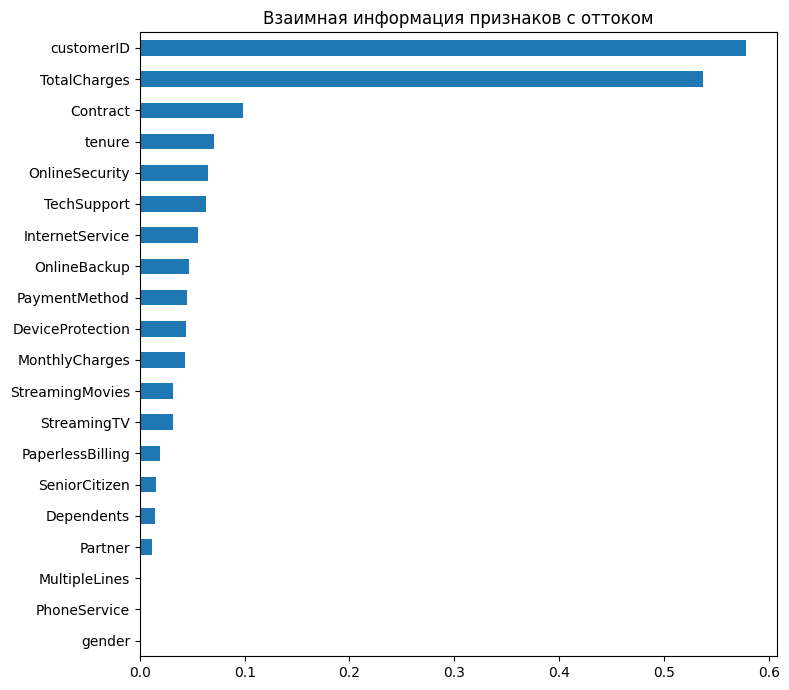

In [22]:
from sklearn.feature_selection import mutual_info_classif

X = df.drop(columns=['Churn'])
y = df['Churn'].eq('Yes').astype(int)

is_cat = np.array([not pd.api.types.is_numeric_dtype(X[c]) for c in X.columns])
X_codes = X.apply(lambda s: s.astype('category').cat.codes if not pd.api.types.is_numeric_dtype(s) else s)

mi = pd.Series(mutual_info_classif(X_codes, y, discrete_features=is_cat, random_state=0),
               index=X.columns).sort_values()

mi.plot(kind='barh', figsize=(8, 7))
plt.title('Взаимная информация признаков с оттоком')
plt.tight_layout()
plt.show()

Рейтинг совпадает с тем, что мы видели на графиках: сильнее всего с оттоком связаны тип контракта, срок жизни клиента, онлайн-защита и техподдержка. Пол, телефонная связь и наличие нескольких линий почти бесполезны.

## Correlation is not causation

По-русски: **корреляция не означает причинно-следственную связь**.

Важно различать два понятия:

* **связь (зависимость)** — величины меняются согласованно: когда растёт одна, в среднем растёт (или падает) другая. Именно это измеряет корреляция;
* **причинно-следственная связь** — изменение одной величины *вызывает* изменение другой.

Корреляция говорит только о первом. Высокая корреляция может возникнуть по трём причинам:

1. **X действительно влияет на Y.** Например, температура на улице влияет на продажи мороженого.
2. **Есть третий фактор, который влияет и на X, и на Y.** Чем больше пожарных приехало на пожар, тем больше ущерб. Но пожарные не причина ущерба: и число пожарных, и ущерб определяются размером пожара. Такой общий фактор называют **конфаундером**.
3. **Случайность.** Если перебрать очень много пар признаков, какие-то из них совпадут просто случайно.

Ещё пример: доход человека положительно связан с его средним баллом в университете. Значит ли это, что хорошие оценки *вызывают* высокий доход? Не обязательно: и на оценки, и на доход могут влиять общие факторы — способности, трудолюбие, вуз, семья. По одной корреляции этого не различить.

**Запомните: корреляция показывает связь, но не говорит, что является причиной.**

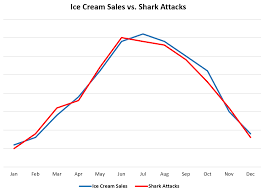

На картинке видно, что продажи мороженого и число нападений акул ведут себя одинаково по месяцам, то есть корреляция между ними большая положительная. Но продажи мороженого, конечно, не вызывают нападения акул. Здесь есть общая причина — лето: жарко, люди покупают больше мороженого и чаще купаются в море.

## Парадокс Симпсона: пример на наших данных

Посмотрим, как третий фактор может не просто создать связь, а **развернуть её в обратную сторону**.

Сравним клиентов с большими суммарными платежами (`TotalCharges` выше медианы) и с маленькими.

In [29]:
churn = df['Churn'].eq('Yes')
total_level = np.where(df['TotalCharges'] > df['TotalCharges'].median(),
                       'TotalCharges выше медианы', 'ниже медианы')

churn.groupby(total_level).mean().round(3)

,Churn
TotalCharges выше медианы,0.187
ниже медианы,0.343


Кажется, что чем больше клиент заплатил, тем **реже** он уходит (19% против 34%).

Но давайте посмотрим отдельно внутри каждой когорты по сроку жизни клиента (когорты мы сделали выше).

In [34]:
print(pd.crosstab(tenure_groups, total_level, values=churn, aggfunc='mean',
                  colnames=['TotalCharges']).round(3))

print('\nКорреляция TotalCharges и оттока по всем клиентам:',
      round(df['TotalCharges'].corr(churn.astype(int)), 2))
print('Корреляция внутри когорт:')
for group, part in df.groupby(tenure_groups, observed=True):
    print(f'  {group}: {part["TotalCharges"].corr(part["Churn"].eq("Yes").astype(int)):.2f}')

TotalCharges  TotalCharges выше медианы  ниже медианы
tenure                                               
0–6 мес                             NaN         0.529
7–12                                NaN         0.359
13–24                             0.423         0.219
25–48                             0.263         0.040
49–72                             0.103         0.026

Корреляция TotalCharges и оттока по всем клиентам: -0.2
Корреляция внутри когорт:
  0–6 мес: 0.10
  7–12: 0.39
  13–24: 0.29
  25–48: 0.25
  49–72: 0.13


Внутри когорт картина **обратная**: среди клиентов с похожим сроком жизни те, кто заплатил больше, уходят **чаще**. Например, в когорте 25–48 месяцев: 26% против 4%. (В первых двух когортах нет клиентов с `TotalCharges` выше медианы: они просто не успели столько заплатить.)

Корреляция `TotalCharges` с оттоком по всем клиентам отрицательная (−0.20), а внутри каждой когорты положительная (от 0.10 до 0.39).

Почему так? `TotalCharges` в основном определяется сроком жизни: давние клиенты накопили большие суммы и при этом уходят редко. В общей картине мы на самом деле видим влияние `tenure`, а не платежей. Когда срок жизни зафиксирован, проявляется другая связь: дорогой тариф → больше отток.

Это и есть **парадокс Симпсона**: связь во всех данных может быть противоположна связи внутри каждой подгруппы. Мораль: прежде чем делать вывод по корреляции, подумайте, какой третий фактор может за ней стоять.

# Итоги: инсайты и гипотезы

### Что мы узнали (факты из данных)

1. Ушло **26.5%** клиентов: классы несбалансированы.
2. **Тип контракта** — самый сильный фактор: отток 43% при помесячном контракте, 11% при годовом, 3% при двухлетнем. Доверительные интервалы не пересекаются.
3. **Новые клиенты уходят чаще всего**: из пришедших за последние полгода ушло 53%, среди тех, кто с компанией больше 4 лет, около 10%. Медианный срок жизни ушедших — 10 месяцев против 38 у оставшихся.
4. **Оптоволокно**: отток 42% против 19% у DSL и 7% у клиентов без интернета. Самая рискованная комбинация — помесячный контракт + оптоволокно: 55% оттока, и это почти треть всех клиентов.
5. **Оплата электронным чеком**: отток 45% против 15–19% при остальных способах.
6. Клиенты **без онлайн-защиты и техподдержки** уходят почти в 3 раза чаще, чем с ними (около 42% против 15%).
7. Ушедшие платят **больше в месяц** (медиана 80 против 64). При одинаковом сроке жизни более высокие платежи связаны с большим оттоком (парадокс Симпсона).
8. **Пенсионеры** уходят чаще (42% против 24%), клиенты без партнёра и без иждивенцев — тоже.
9. **Пол, телефонная связь и несколько линий почти не связаны с оттоком**: для пола разница легко объясняется случайностью (тест перемешиванием), взаимная информация у этих признаков около нуля.
10. Технические наблюдения:
    * `TotalCharges ≈ tenure × MonthlyCharges` (корреляция 0.9996);
    * `No internet service` в шести колонках дублирует `InternetService = No`;
    * 11 пробелов в `TotalCharges` — это новые клиенты с `tenure = 0`.

### Гипотезы: что проверять дальше

Это не выводы, а предположения: EDA показывает связи, но не причины.

1. **Долгосрочный контракт удерживает клиентов.** Но, возможно, долгосрочные контракты просто выбирают изначально лояльные клиенты. Различить это можно только экспериментом: например, предложить скидку за переход на годовой контракт случайной половине клиентов с помесячным контрактом и сравнить отток.
2. **С оптоволокном что-то не так: цена или качество.** Оптоволокно дороже. Возможно, клиенты недовольны соотношением цены и качества или уходят к конкурентам с более дешёвыми тарифами. Стоит посмотреть жалобы и данные о качестве связи.
3. **Первые месяцы — критический период.** Онбординг (приветственные бонусы, звонок через месяц после подключения) может снизить отток новичков.
4. **Автоплатёж удерживает клиентов.** При оплате электронным чеком клиент каждый месяц заново решает, платить ли. Можно проверить: стимулировать переход на автоплатёж и сравнить отток.
5. **Допуслуги (защита, техподдержка) повышают лояльность.** Или их просто покупают более вовлечённые клиенты — тоже нужна проверка экспериментом.

### Что это значит для модели

* Accuracy не подходит из-за дисбаланса классов: будем смотреть на precision, recall, ROC-AUC.
* Самые информативные признаки: `Contract`, `tenure`, `OnlineSecurity`, `TechSupport`, `InternetService`, `PaymentMethod`.
* `gender` и `PhoneService` почти не несут информации — кандидаты на удаление.
* `TotalCharges` почти дублирует `tenure × MonthlyCharges`: для линейных моделей стоит оставить что-то одно.